# TouNum, livrable 3 : captioning d'images et workflow complet

Projet Leyenda, CESI. Rendu de notre groupe pour TouNum : troisième module du prototype et assemblage des trois
livrables en un workflow reproductible.

Équipe : Mathieu, Matthis et Julien.

---
## 0. Contexte métier et objectif

TouNum numérise des documents pour ses clients et veut proposer un service de légendage automatique : pour chaque
photo d'une archive numérisée, une courte phrase qui la décrit, afin de pouvoir chercher dans l'archive par
contenu. Le workflow que nous avons conçu comporte trois modules :

1. Filtrage : ne garder que les photos (livrable 1) ;
2. Prétraitement : retirer le bruit des photos qui en ont besoin (livrable 2) ;
3. **Captioning : écrire une légende pour chaque photo (ce livrable)**.

Notre modèle de captioning suit l'approche donnée dans l'énoncé. Un réseau convolutif (CNN), pré-entraîné pour la
classification d'images, transforme chaque image en un ensemble de vecteurs de features. Un réseau récurrent (RNN)
écrit ensuite la légende un mot à la fois, chaque mot dépendant de l'image et des mots déjà écrits. Le modèle est
entraîné sur MS COCO, un dataset public de photos accompagnées chacune de cinq légendes écrites par des personnes.

La dernière partie du notebook assemble les trois livrables en un seul workflow qui prend un dossier d'images et
renvoie un tableau de légendes. Sa dernière cellule est celle que nous lancerons le jour de la soutenance, sur un
nouveau dossier.

### Plan
| Section | Contenu |
|---|---|
| 1 | Environnement |
| 2 | Les données MS COCO : échantillonnage, téléchargement, exemples |
| 3 | Prétraitement du texte : nettoyage, vocabulaire, encodage |
| 4 | Prétraitement des images par un CNN pré-entraîné (InceptionV3) |
| 5 | Modèle de captioning : architecture, perte, optimiseur |
| 6 | Entraînement et courbes d'apprentissage, avec et sans attention |
| 7 | Évaluation sur les images de test : scores BLEU, exemples, cartes d'attention |
| 8 | Étude de cas : photos bruitées, débruitage et qualité des légendes |
| 9 | Le workflow complet (livrables 1, 2 et 3) sur un dossier de démonstration |
| 10 | Conclusion, limites, et la cellule à lancer sur un nouveau dossier |

### Exécution
`bash scripts/run_notebook.sh 3 full` reconstruit le `.ipynb` à partir de ce fichier `.py` et l'exécute. Il faut
une connexion internet à la première exécution (légendes et images COCO, poids ImageNet d'InceptionV3) et les
modèles sauvegardés des livrables 1 et 2 (`models/photo_classifier.keras`, `models/denoiser.keras`). Les features
des images sont calculées une fois et mises en cache dans `data/features/`. `bash scripts/run_notebook.sh 3 quick`
lance une version très courte sur quelques centaines d'images pour vérifier que tout s'exécute ; elle ne touche
jamais au livrable ni aux modèles sauvegardés.

## 1. Environnement

In [1]:
import os
import sys
import json
import time
import shutil
import inspect
import tempfile
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")      # masque les logs C++ de TensorFlow (autotuning GPU)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import tounum_gpu
tounum_gpu.setup()                                      # utilise le GPU NVIDIA s'il y en a un (src/tounum_gpu.py)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from IPython.display import display, Markdown
import tensorflow as tf
import keras

from tounum_cls import config as cls_config, data as cls_data
from tounum_denoise import config as dn_config, data as dn_data, modeling as dn_modeling
from tounum_caption import config, data, features, model, evaluation, pipeline

QUICK = os.environ.get("TOUNUM_QUICK") == "1"
EPOCHS = 2 if QUICK else 60                 # borne haute : l'early stopping décide quand s'arrêter
PATIENCE = 6
SIZES = {"train": 2_000, "val": 300, "test": 300} if QUICK else None    # QUICK : quelques images par jeu
N_BLEU_EPOCH = 300 if QUICK else 500        # images de validation légendées à la fin de chaque époque
N_CASE = 100 if QUICK else 1_000            # images de test utilisées dans l'étude de cas (section 8)
LOADER = dict(workers=8, use_multiprocessing=False)   # 8 threads préparent les batchs pendant que le GPU entraîne
SAVE_DIR = Path(tempfile.gettempdir()) / "tounum_quick" if QUICK else config.MODELS_DIR   # QUICK ne touche jamais models/
FEATURES_DIR = SAVE_DIR / "features" if QUICK else config.FEATURES_DIR
SPLITS = ("train", "val", "test")
# noms français des colonnes du tableau renvoyé par le pipeline, pour l'affichage
COLS_FR = {"file": "fichier", "p_photo": "P(photo)", "is_photo": "photo", "noise_sigma": "sigma estimé",
           "denoised": "débruitée", "caption": "légende"}
if QUICK:
    os.environ["TOUNUM_MODELS_DIR"] = str(SAVE_DIR)     # lu par la dernière cellule du notebook

keras.utils.set_random_seed(config.SEED)
pd.set_option("display.precision", 3)
pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", 90)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100


def milliers(n):
    """Entier avec une espace comme séparateur de milliers (12 000)."""
    return f"{int(n):,}".replace(",", " ")


print(f"Python {sys.version.split()[0]} | TensorFlow {tf.__version__} | Keras {keras.__version__} | numpy {np.__version__}")
print("GPU :", tf.config.list_physical_devices("GPU") or "aucun (exécution sur CPU)")
print(f"Graine : {config.SEED} | mode QUICK : {QUICK} | époques max : {EPOCHS}")

I0000 00:00:1791364125.242193  314126 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1791364125.825575  314126 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Python 3.12.13 | TensorFlow 2.21.0 | Keras 3.15.1 | numpy 2.5.3
GPU : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Graine : 42 | mode QUICK : False | époques max : 60


## 2. Les données MS COCO

MS COCO 2017 compte environ 118 000 images d'entraînement et 5 000 images de validation : des scènes de la vie
courante avec des personnes, des animaux, des véhicules et des objets. Chaque image est accompagnée de cinq
légendes écrites par des personnes différentes. Nous utilisons un échantillon :

| Jeu | Source | Images | Rôle |
|---|---|---|---|
| `train` | COCO `train2017` | 80 000 tirées au hasard | apprendre les poids |
| `val` | COCO `train2017`, sans recouvrement avec `train` | 2 000 | suivre l'entraînement, early stopping, choix du modèle |
| `test` | COCO `val2017` | 2 000 | mesure finale uniquement |

Les images sont téléchargées une par une depuis le serveur COCO (`data.download_images`), ce qui évite l'archive
de 18 Go. Notre première version utilisait 28 000 images d'entraînement, une taille pensée pour un CPU.
L'entraînement tourne maintenant sur GPU, où davantage d'images coûtent peu de temps, et la courbe d'apprentissage
de la section 6.1 montre comment les scores évoluent avec le nombre d'images d'entraînement. Nous utilisons donc
80 000 images (environ 400 000 légendes). Aller plus loin est possible, mais chaque tranche de 10 000 images
supplémentaires ajoute 2,6 Go de features à garder en mémoire.

Les 148 photos bruitées du livrable 2 sont des images d'entraînement de COCO (nous avons retrouvé leurs originaux
propres au livrable 2). Certaines tombent dans notre échantillon. Nous les en retirons, pour que l'étude de cas de
la section 8 et la démonstration de la section 9 portent sur des images que le modèle de captioning n'a jamais
vues.

MS COCO est annoté en anglais : les légendes que génère notre modèle sont donc en anglais. Nous revenons sur ce
point dans les limites (section 10).

In [2]:
t0 = time.perf_counter()
data.download_annotations()
images = data.sample_images()
originals = pd.read_csv(dn_config.ORIGINALS_CSV)
n_sampled = len(images)
images = data.exclude_images(images, originals["coco_id"])
n_excluded = n_sampled - len(images)
if QUICK:
    images = images[images.groupby("split").cumcount() < images["split"].map(SIZES)].reset_index(drop=True)
failed = data.download_images(images)
assert not failed, f"{len(failed)} images n'ont pas pu être téléchargées"
captions = data.captions_for(images)

table = pd.DataFrame({"images": images["split"].value_counts(), "légendes": captions["split"].value_counts()}).loc[list(SPLITS)]
table["légendes par image"] = table["légendes"] / table["images"]
display(table)
print(f"{n_excluded} images échantillonnées retirées (originaux propres des photos bruitées du livrable 2) | "
      f"prêt en {time.perf_counter() - t0:.0f} s")

,images,légendes,légendes par image
split,,,
train,79901,399713,5.003
val,1997,9986,5.001
test,2000,10005,5.003


102 images échantillonnées retirées (originaux propres des photos bruitées du livrable 2) | prêt en 9 s


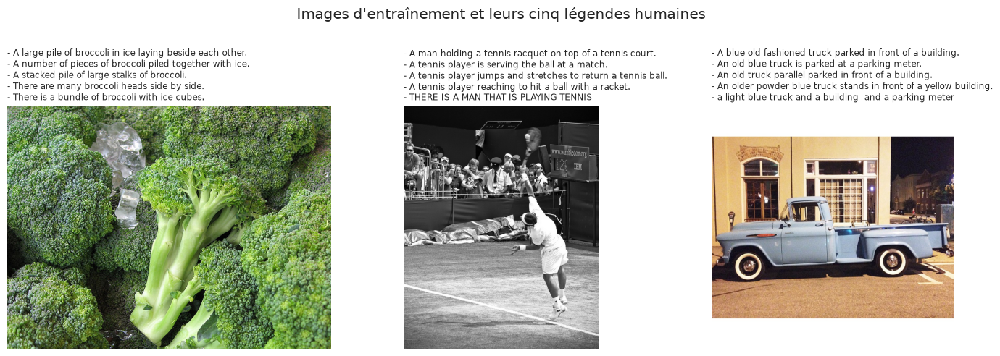

In [3]:
shown = images[images["split"] == "train"].sample(3, random_state=config.SEED)
fig, axes = plt.subplots(1, 3, figsize=(14, 4.9))
for ax, (_, row) in zip(axes, shown.iterrows()):
    ax.imshow(cls_data.read_rgb(row["path"]))
    ax.axis("off")
    caps = captions.loc[captions["image_id"] == row["image_id"], "caption"].tolist()
    ax.set_title("\n".join(f"- {c.strip()}" for c in caps), fontsize=8.5, loc="left")
plt.suptitle("Images d'entraînement et leurs cinq légendes humaines", y=1.0)
plt.tight_layout()
plt.show()

Les cinq légendes d'une image décrivent la même scène avec des mots et des détails différents. C'est important
pour l'évaluation : une légende générée est comparée aux cinq (section 7), puisqu'il n'y a pas une seule bonne
réponse.

## 3. Prétraitement du texte

Les légendes passent par trois étapes avant que le réseau ne les voie :

1. **Nettoyage** (`data.clean_caption`) : minuscules, lettres uniquement (ponctuation et chiffres retirés), et
   ajout de deux marqueurs, `startseq` au début et `endseq` à la fin. `startseq` est la première entrée du
   décodeur ; générer `endseq` est la façon dont le modèle indique que la légende est terminée.
2. **Vocabulaire** (`data.build_vocabulary`) : les 5 000 mots les plus fréquents des légendes *d'entraînement*.
   L'indice 0 est réservé au padding et l'indice 1 aux mots inconnus (`[UNK]`), qui remplacent les mots rares.
3. **Encodage** (`data.encode`) : chaque légende devient une séquence de longueur fixe de 22 indices de mots,
   complétée par des zéros. Les légendes plus longues sont coupées mais gardent leur `endseq`.

In [4]:
ex = captions.sample(4, random_state=config.SEED)
display(pd.DataFrame({"légende brute": ex["caption"].str.strip().to_numpy(), "nettoyée": ex["clean"].to_numpy()}))

vocab = data.build_vocabulary(captions.loc[captions["split"] == "train", "clean"])
word_counts = pd.Series(Counter(" ".join(captions.loc[captions["split"] == "train", "clean"]).split()))
word_counts = word_counts.drop([config.START, config.END])          # les marqueurs ne sont pas des mots
coverage = word_counts[word_counts.index.isin(set(vocab))].sum() / word_counts.sum()
lengths = captions["clean"].str.split().str.len()
fits = (lengths <= config.MAX_LEN).mean()

tokens = {s: data.encode(captions.loc[captions["split"] == s, "clean"], vocab) for s in SPLITS}
image_index = {s: captions.loc[captions["split"] == s, "image_index"].to_numpy() for s in SPLITS}
refs = {s: data.references(captions, s) for s in SPLITS}

sample = ex["clean"].iloc[0]
ids = data.encode([sample], vocab)[0]
print(f"'{sample}'\n-> {ids.tolist()}\n-> retour au texte : '{data.decode(ids, vocab)}'")

,légende brute,nettoyée
0,"Blue and pink, and white frosted cupcakes with on a plate.",startseq blue and pink and white frosted cupcakes with on a plate endseq
1,A plate with a very bright colored decorated cake.,startseq a plate with a very bright colored decorated cake endseq
2,A group of people riding skis across a snow covered slope.,startseq a group of people riding skis across a snow covered slope endseq
3,A person in a boat on the shore of a beach while another person stands outside it.,startseq a person in a boat on the shore of a beach while another person stands outsid...


'startseq blue and pink and white frosted cupcakes with on a plate endseq'
-> [4, 60, 10, 262, 10, 22, 1301, 1293, 9, 5, 2, 43, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0]
-> retour au texte : 'blue and pink and white frosted cupcakes with on a plate'


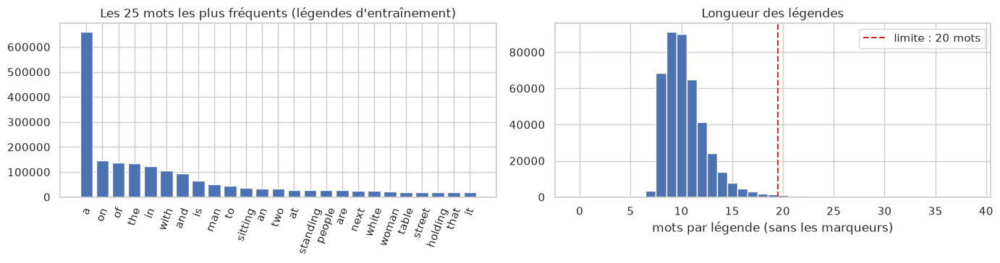

**Résultats.** Les légendes d'entraînement utilisent **22 431** mots distincts. Le vocabulaire en garde 4 996 (plus le padding, `[UNK]` et les deux marqueurs), qui couvrent **98.7%** des occurrences de mots : les autres mots sont rares (noms propres, fautes de frappe) et deviennent `[UNK]`. **99.4%** des légendes tiennent en 22 tokens sans être coupées. La légende médiane compte 10 mots.

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
top = word_counts.nlargest(25)
axes[0].bar(top.index, top.to_numpy())
axes[0].tick_params(axis="x", rotation=70)
axes[0].set_title("Les 25 mots les plus fréquents (légendes d'entraînement)")
axes[1].hist(lengths - 2, bins=np.arange(0, 40) - 0.5)
axes[1].axvline(config.MAX_LEN - 2.5, color="tab:red", ls="--", label=f"limite : {config.MAX_LEN - 2} mots")
axes[1].set_xlabel("mots par légende (sans les marqueurs)")
axes[1].set_title("Longueur des légendes")
axes[1].legend()
plt.tight_layout()
plt.show()

display(Markdown(
    f"**Résultats.** Les légendes d'entraînement utilisent **{milliers(len(word_counts))}** mots distincts. Le "
    f"vocabulaire en garde {milliers(len(vocab) - 4)} (plus le padding, `[UNK]` et les deux marqueurs), qui couvrent "
    f"**{coverage:.1%}** des occurrences de mots : les autres mots sont rares (noms propres, fautes de frappe) et "
    f"deviennent `[UNK]`. **{fits:.1%}** des légendes tiennent en {config.MAX_LEN} tokens sans être coupées. La "
    f"légende médiane compte {int(np.median(lengths - 2))} mots."
))

## 4. Prétraitement des images par un CNN pré-entraîné

L'énoncé demande que les images soient prétraitées par un CNN pré-entraîné pour la classification. Nous utilisons
**InceptionV3**, entraîné sur ImageNet (1,2 million d'images, 1 000 classes). Ses couches convolutives ont appris
à détecter des contours, des textures, des parties d'objets et des objets entiers, ce dont une légende a besoin.
Nous retirons sa tête de classification et gardons la sortie de son dernier bloc convolutif : une grille 8 x 8 de
2 048 features. Chacune des 64 cases décrit une région de l'image, ce qui permet au décodeur de regarder des
régions différentes pour des mots différents (section 5).

Étapes du prétraitement des images, toutes dans `features.py` :
1. lire le fichier avec ImageIO en RGB (les images en niveaux de gris et RGBA sont converties, comme au
   livrable 1) ;
2. redimensionner en 299 x 299 pixels, la taille d'entrée d'InceptionV3 (les proportions ne sont pas gardées) ;
3. ramener les pixels de [0, 255] à [-1, 1], la plage sur laquelle InceptionV3 a été entraîné (dans le modèle) ;
4. passer l'image dans le réseau gelé et aplatir la sortie 8 x 8 x 2048 en 64 vecteurs de 2 048 valeurs.

InceptionV3 est gelé : ses 21,8 millions de poids ne sont pas entraînés ici. Les features de chaque image sont
donc toujours les mêmes : nous les calculons une seule fois et les stockons sur disque (en flottants 16 bits, ce
qui divise la taille par deux). L'entraînement ne fait ensuite que lire ces fichiers, ce qui rend chaque époque
beaucoup plus rapide. C'est aussi ce qui répond à la contrainte de mémoire de l'énoncé : le décodeur ne charge
jamais les images elles-mêmes, seulement leur représentation compacte.

In [6]:
print(inspect.getsource(features.build_encoder))
encoder = features.build_encoder()
encoder.summary()

def build_encoder(weights: str | None = "imagenet") -> keras.Model:
    """InceptionV3 gelé, sans sa tête de classification.

    Entrée : images RGB uint8 (299, 299, 3) ; la mise à l'échelle [-1, 1] attendue par InceptionV3 est faite dans
    le modèle. Sortie : (64, 2048) float32, la grille 8 x 8 du dernier bloc convolutif aplatie en 64 régions.
    `weights=None` (tests) évite de télécharger les poids ImageNet.
    """
    size = config.FEATURE_IMG_SIZE
    base = keras.applications.InceptionV3(include_top=False, weights=weights, input_shape=(size, size, 3))
    base.trainable = False
    inputs = keras.Input(shape=(size, size, 3), name="image")
    x = layers.Rescaling(1.0 / 127.5, offset=-1.0, name="rescaling")(inputs)
    x = base(x, training=False)
    outputs = layers.Reshape((config.N_REGIONS, config.FEATURE_DIM), name="regions")(x)
    return keras.Model(inputs, outputs, name="inceptionv3_encoder")



Model: "inceptionv3_encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 299, 299, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 299, 299, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ inception_v3 (Functional)       │ (None, 8, 8, 2048)     │    21,802,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ regions (Reshape)               │ (None, 64, 2048)       │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,802,784 (83.17 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 21,802,784 (83.17 MB)

In [7]:
feats = {}
for s in SPLITS:
    t0 = time.perf_counter()
    cached = (FEATURES_DIR / f"{s}.npy").exists()
    feats[s] = features.extract_features(encoder, images.loc[images["split"] == s, "path"], FEATURES_DIR / f"{s}.npy")
    print(f"{s} : features {feats[s].shape}, {feats[s].nbytes / 1e9:.2f} Go, "
          + (f"lues depuis le cache en {time.perf_counter() - t0:.0f} s" if cached else
             f"calculées en {time.perf_counter() - t0:.0f} s"))

train : features (79901, 64, 2048), 20.95 Go, lues depuis le cache en 5 s
val : features (1997, 64, 2048), 0.52 Go, lues depuis le cache en 0 s


test : features (2000, 64, 2048), 0.52 Go, lues depuis le cache en 0 s


Pour voir ce que le réseau pré-entraîné sait déjà, nous lançons l'InceptionV3 complet, avec sa tête de
classification ImageNet, sur quelques images de test (préparées exactement comme ci-dessus) et affichons ses trois
classes ImageNet les plus probables. Notre encodeur est ce même réseau sans les dernières couches : ses features
portent cette connaissance des objets. ImageNet ne contient que des classes d'objets, donc le réseau sait nommer un
objet mais pas décrire une scène ou une action : c'est le rôle du décodeur.

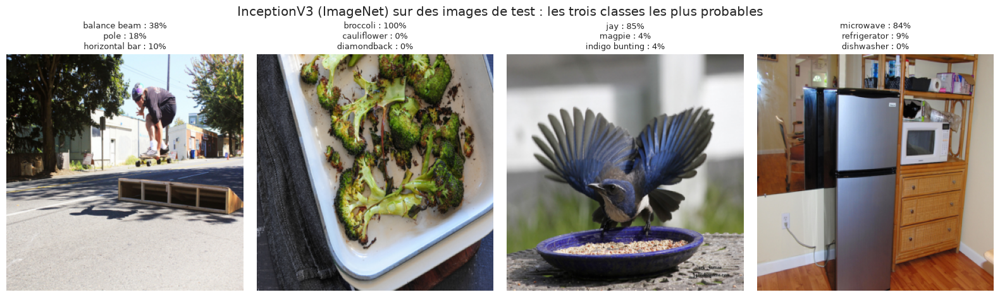

**Résultats.** InceptionV3 transforme chaque image en 64 vecteurs de 2 048 valeurs. Les features des 83 898 images occupent 22.0 Go sur disque et en mémoire.

In [8]:
imagenet_cnn = keras.applications.InceptionV3(weights="imagenet")
shown_test = images[images["split"] == "test"].head(4)
batch = np.stack([features.load_image(p) for p in shown_test["path"]])
top3 = keras.applications.inception_v3.decode_predictions(
    imagenet_cnn.predict(keras.applications.inception_v3.preprocess_input(batch.astype("float32")), verbose=0), top=3)
fig, axes = plt.subplots(1, 4, figsize=(16, 4.6))
for ax, img, preds in zip(axes, batch, top3):
    ax.imshow(img)
    ax.set_title("\n".join(f"{name.replace('_', ' ')} : {p:.0%}" for _, name, p in preds), fontsize=9)
    ax.axis("off")
plt.suptitle("InceptionV3 (ImageNet) sur des images de test : les trois classes les plus probables", y=1.02)
plt.tight_layout()
plt.show()
del imagenet_cnn

display(Markdown(
    f"**Résultats.** InceptionV3 transforme chaque image en {config.N_REGIONS} vecteurs de "
    f"{milliers(config.FEATURE_DIM)} valeurs. Les features des {milliers(sum(len(f) for f in feats.values()))} images "
    f"occupent {sum(f.nbytes for f in feats.values()) / 1e9:.1f} Go sur disque et en mémoire."
))

## 5. Modèle de captioning

### 5.1 Architecture

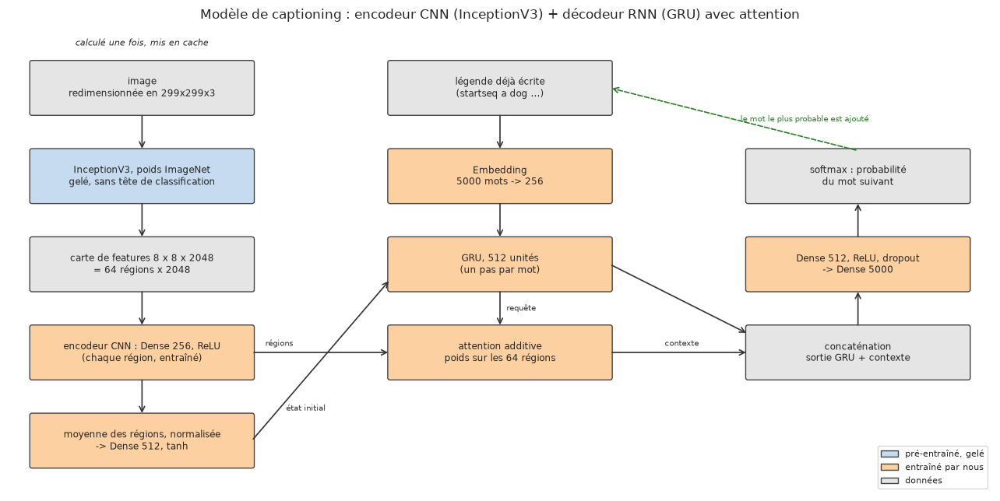

In [9]:
evaluation.draw_architecture(vocab_size=len(vocab))
plt.show()

Le modèle a une partie CNN et une partie RNN, comme demandé dans l'énoncé :

- **Partie CNN.** InceptionV3 (gelé, section 4) suivi d'une couche `Dense(256, ReLU)` entraînable, appliquée à
  chacune des 64 régions. Cette projection adapte les features ImageNet à la tâche de captioning. La moyenne des
  régions projetées, normalisée (`LayerNormalization`) et passée dans `Dense(512, tanh)`, donne l'état initial du
  RNN : le décodeur démarre avec un résumé de toute l'image. La normalisation éloigne la `tanh` de la saturation ;
  sans elle, une de nos premières versions finissait parfois par donner le même état initial à toutes les images.
- **Partie RNN.** Les mots déjà écrits passent par une couche `Embedding` (chaque mot devient un vecteur de 256
  valeurs, appris pendant l'entraînement) puis par une couche **GRU** de 512 unités. Un GRU est une couche
  récurrente avec des portes qui décident quoi garder des mots précédents ; il fait le même travail qu'un LSTM
  avec moins de paramètres.
- **Attention.** À chaque pas, la sortie du GRU est comparée à chacune des 64 régions (attention additive, dite de
  Bahdanau). Les scores passent par un softmax, ce qui donne 64 poids dont la somme vaut 1, et la somme pondérée
  des régions (le *contexte*) indique au modèle où regarder pour le mot suivant. Sans attention, l'image n'entrerait
  que par l'état initial et le décodeur devrait s'en souvenir pendant toute la phrase.
- **Sortie.** La sortie du GRU et le contexte sont concaténés, passent par `Dense(512, ReLU)` et un dropout, et une
  dernière couche `Dense` donne un score par mot du vocabulaire. Un softmax transforme les scores en probabilité
  que chaque mot soit le suivant.

Le code ci-dessous est celui utilisé pour l'entraînement (`src/tounum_caption/model.py`). Le modèle n'utilise que
des couches Keras standard, donc le fichier sauvegardé se recharge sans code spécifique.

In [10]:
print(inspect.getsource(model.build_captioner))
keras.utils.set_random_seed(config.SEED)
captioner = model.build_captioner(vocab_size=len(vocab))
captioner.summary()

def build_captioner(
    vocab_size: int = config.VOCAB_SIZE,
    attention: bool = True,
    embed_dim: int = config.EMBED_DIM,
    units: int = config.UNITS,
    dropout: float = 0.3,
    learning_rate: float = 1e-3,
    name: str | None = None,
) -> keras.Model:
    """Décodeur de légendes entraîné en teacher forcing : prédit le mot t+1 à partir de l'image et des mots 1..t.

    Entrées : `image_features` (64, 2048), les régions InceptionV3, et `tokens` (T,), la légende déjà écrite.
    Sortie : logits (T, vocab_size) du mot suivant à chaque position.
    Partie CNN : une couche Dense entraînable projette chaque région en `embed_dim` ; leur moyenne, normalisée,
    donne l'état initial du GRU. Sans la normalisation, la tanh de l'état initial peut saturer tôt dans
    l'entraînement : toutes les images reçoivent alors le même état et le modèle sans attention ignore l'image.
    Partie RNN : Embedding -> GRU. Avec `attention=True`, à chaque pas la sortie du GRU regarde les 64 régions


Model: "captioner_attention"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image_features      │ (None, 64, 2048)  │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cnn_encoder (Dense) │ (None, 64, 256)   │    524,544 │ image_features[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tokens (InputLayer) │ (None, None)      │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ image_mean          │ (None, 256)       │          0 │ cnn_encoder[0][0] │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, None, 256) │  1,280,000 │ tokens[0][0]      │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ image_norm          │ (None, 256)       │        512 │ image_mean[0][0]  │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_dropout   │ (None, None, 256) │          0 │ embedding[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ initial_state       │ (None, 512)       │    131,584 │ image_norm[0][0]  │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gru (GRU)           │ (None, None, 512) │  1,182,720 │ embedding_dropou… │
│                     │                   │            │ initial_state[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention_query     │ (None, None, 256) │    131,328 │ gru[0][0]         │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention           │ [(None, None,     │        256 │ attention_query[… │
│ (AdditiveAttention) │ 256), (None,      │            │ cnn_encoder[0][0] │
│                     │ None, 64)]        │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gru_and_context     │ (None, None, 768) │          0 │ gru[0][0],        │
│ (Concatenate)       │                   │            │ attention[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ hidden (Dense)      │ (None, None, 512) │    393,728 │ gru_and_context[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ hidden_dropout      │ (None, None, 512) │          0 │ hidden[0][0]      │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ next_word (Dense)   │ (None, None,      │  2,565,000 │ hidden_dropout[0… │
│                     │ 5000)             │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 6,209,672 (23.69 MB)

 Trainable params: 6,209,672 (23.69 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:
parts = {"partie CNN (projection, état initial)": ["cnn_encoder", "image_norm", "initial_state"],
         "partie RNN (embedding, GRU)": ["embedding", "gru"],
         "attention": ["attention_query", "attention"],
         "couches de sortie": ["hidden", "next_word"]}
param_table = pd.DataFrame({"paramètres": {k: sum(captioner.get_layer(n).count_params() for n in v) for k, v in parts.items()}})
param_table["part"] = param_table["paramètres"] / param_table["paramètres"].sum()
display(param_table)

,paramètres,part
"partie CNN (projection, état initial)",656640,0.106
"partie RNN (embedding, GRU)",2462720,0.397
attention,131584,0.021
couches de sortie,2958728,0.476


### 5.2 Entraînement : teacher forcing, perte et optimiseur

| Élément | Choix | Raison |
|---|---|---|
| Entrées / cibles | la légende sans son dernier token / la légende sans son premier token | à chaque position, le modèle apprend à prédire le mot suivant (**teacher forcing** : pendant l'entraînement, il reçoit toujours les vrais mots précédents) |
| **Perte** | entropie croisée catégorielle (sparse) sur le mot suivant, moyennée sur les vrais mots (padding ignoré) | elle vaut $-\log p(\text{bon mot suivant})$ : faible quand le modèle donne une forte probabilité au mot qu'a écrit la personne |
| **Optimiseur** | **Adam**, taux d'apprentissage $10^{-3}$, norme du gradient plafonnée à 5 | choix par défaut fiable ; le plafonnement évite les gradients ponctuellement très grands des réseaux récurrents |
| Batchs | 64 légendes ; une légende par image et par époque, retirée au sort à chaque époque | les époques restent courtes et les cinq légendes sont vues au fil des époques |
| Régularisation | dropout 0.3 sur les vecteurs de mots et avant la sortie, early stopping sur la perte de validation (patience 6, meilleurs poids restaurés) | limite le sur-apprentissage |
| Métriques suivies | accuracy sur le mot suivant (padding ignoré) et, à la fin de chaque époque, BLEU-4 sur 500 images de validation | la perte mesure des mots isolés ; BLEU mesure des légendes générées entières |

**Générer une légende** (`model.generate`) : on part de `startseq`, on demande au modèle les probabilités du mot
suivant, on garde le plus probable (*décodage glouton*), on l'ajoute et on recommence jusqu'à `endseq` ou
20 mots. Le modèle ne voit jamais la vraie légende à ce stade, ses propres erreurs peuvent donc s'accumuler : c'est
la principale différence entre l'entraînement et l'utilisation. Le padding et `[UNK]` ne sont jamais choisis,
puisqu'une légende contenant un mot inconnu est inutile.

## 6. Entraînement et courbes d'apprentissage

Nous entraînons deux versions avec les mêmes données, la même graine et les mêmes réglages : le modèle avec
attention décrit ci-dessus, et le même modèle **sans attention** (l'image n'entre que par l'état initial, comme
dans le modèle *Show and Tell*). La comparaison montre ce qu'apporte l'attention.

In [12]:
VARIANTS = {"avec attention": True, "sans attention": False}
histories, models_, times = {}, {}, {}
for name, attention in VARIANTS.items():
    keras.utils.set_random_seed(config.SEED)
    m = captioner if attention else model.build_captioner(vocab_size=len(vocab), attention=False)
    train_batches = model.CaptionBatches(feats["train"], tokens["train"], image_index["train"], one_per_image=True,
                                         **LOADER)
    val_batches = model.CaptionBatches(feats["val"], tokens["val"], image_index["val"], **LOADER)
    bleu_cb = model.BleuCallback(feats["val"][:N_BLEU_EPOCH], refs["val"][:N_BLEU_EPOCH], vocab)
    t0 = time.perf_counter()
    histories[name] = model.train(m, train_batches, val_batches, epochs=EPOCHS, callbacks=[bleu_cb],
                                  patience=PATIENCE, verbose=0)
    times[name] = time.perf_counter() - t0
    models_[name] = m
    print(f"{name} : {len(histories[name])} époques en {times[name] / 60:.1f} min "
          f"({times[name] / len(histories[name]):.0f} s par époque)")

avec attention : 24 époques en 7.3 min (18 s par époque)


sans attention : 29 époques en 8.2 min (17 s par époque)


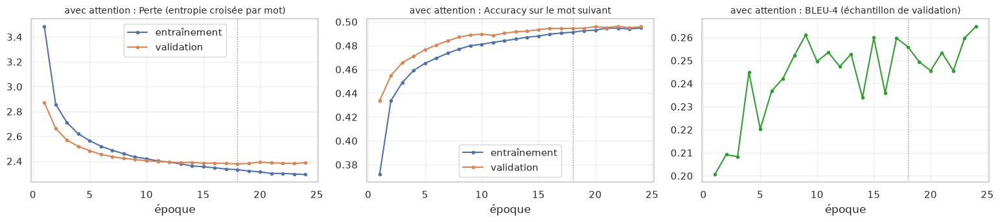

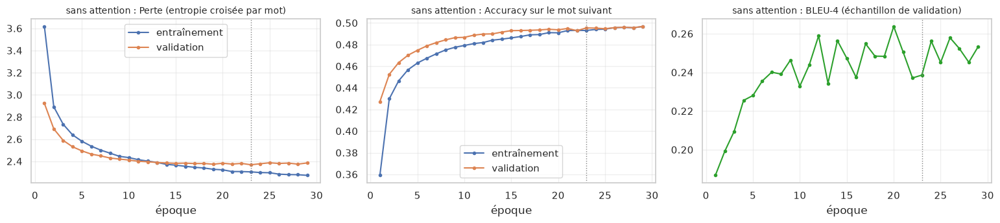

In [13]:
for name, hist in histories.items():
    evaluation.plot_history(hist, name)
    plt.show()

In [14]:
rows = []
for name, hist in histories.items():
    best = hist.loc[hist["val_loss"].idxmin()]
    rows.append({"modèle": name, "paramètres": models_[name].count_params(), "époques effectuées": len(hist),
                 "meilleure époque": int(best["epoch"]), "perte entraînement": best["loss"], "perte validation": best["val_loss"],
                 "acc. mot entraînement": best["masked_accuracy"], "acc. mot validation": best["val_masked_accuracy"],
                 "BLEU-4 validation (500 images)": best["val_bleu4"], "temps (min)": times[name] / 60})
train_table = pd.DataFrame(rows).set_index("modèle")
display(train_table)

,paramètres,époques effectuées,meilleure époque,perte entraînement,perte validation,acc. mot entraînement,acc. mot validation,BLEU-4 validation (500 images),temps (min)
modèle,,,,,,,,,
avec attention,6209672,24,18,2.332,2.377,0.491,0.495,0.256,7.305
sans attention,5947016,29,23,2.304,2.369,0.493,0.495,0.239,8.189


In [15]:
att, noatt = train_table.loc["avec attention"], train_table.loc["sans attention"]
gap = att["perte validation"] - att["perte entraînement"]
hist_att = histories["avec attention"]
after = hist_att.loc[hist_att["epoch"] > att["meilleure époque"], "val_bleu4"]       # BLEU après la meilleure époque
display(Markdown(
    f"**Résultats.** Avec attention, la perte de validation atteint **{att['perte validation']:.3f}** à l'époque "
    f"{int(att['meilleure époque'])} (accuracy sur le mot suivant {att['acc. mot validation']:.3f}, BLEU-4 "
    f"{att['BLEU-4 validation (500 images)']:.3f} sur l'échantillon de validation). Sans attention : "
    f"{noatt['perte validation']:.3f} à l'époque {int(noatt['meilleure époque'])} (accuracy "
    f"{noatt['acc. mot validation']:.3f}, BLEU-4 {noatt['BLEU-4 validation (500 images)']:.3f}). "
    f"À l'époque retenue, la perte de validation du modèle avec attention est à {gap:+.3f} de sa perte "
    "d'entraînement. "
    + ("La perte de validation cesse de s'améliorer pendant que la perte d'entraînement continue de baisser : le "
       "modèle commence à apprendre par cœur les légendes d'entraînement, et l'early stopping garde les poids "
       "d'avant ce point. "
       if histories["avec attention"]["loss"].iloc[-1] < att["perte entraînement"] else "")
    + (f"Le BLEU-4 sur l'échantillon de validation a encore monté après la meilleure époque de perte (jusqu'à "
       f"{after.max():.3f}) : la perte compte aussi la probabilité donnée à des mots que le décodage glouton ne "
       "choisirait pas, les deux ne culminent donc pas au même moment. Arrêter sur le BLEU demanderait un "
       "échantillon de validation plus grand pour être fiable."
       if len(after) and after.max() > att["BLEU-4 validation (500 images)"] + 0.005 else "")
))

**Résultats.** Avec attention, la perte de validation atteint **2.377** à l'époque 18 (accuracy sur le mot suivant 0.495, BLEU-4 0.256 sur l'échantillon de validation). Sans attention : 2.369 à l'époque 23 (accuracy 0.495, BLEU-4 0.239). À l'époque retenue, la perte de validation du modèle avec attention est à +0.046 de sa perte d'entraînement. La perte de validation cesse de s'améliorer pendant que la perte d'entraînement continue de baisser : le modèle commence à apprendre par cœur les légendes d'entraînement, et l'early stopping garde les poids d'avant ce point. Le BLEU-4 sur l'échantillon de validation a encore monté après la meilleure époque de perte (jusqu'à 0.265) : la perte compte aussi la probabilité donnée à des mots que le décodage glouton ne choisirait pas, les deux ne culminent donc pas au même moment. Arrêter sur le BLEU demanderait un échantillon de validation plus grand pour être fiable.

**Lecture des courbes.** La perte d'entraînement est mesurée avec le dropout actif, elle est donc un peu
pessimiste par rapport à la perte de validation. Quand la perte de validation remonte alors que la perte
d'entraînement continue de baisser, le modèle sur-apprend (côté variance) ; l'early stopping garde les poids de la
meilleure époque de validation. La courbe de BLEU-4 est plus bruitée que la perte parce qu'elle est calculée sur
500 légendes générées. Les pistes pour aller plus loin sont listées en section 10 (plus d'images, beam search,
fine-tuning du CNN).

Le choix entre les deux modèles se fait sur **tout le jeu de validation** (2 000 images), avec le BLEU-4 des
légendes générées, plus proche de l'usage réel que la perte.

In [16]:
val_captions = {name: model.generate(m, feats["val"], vocab) for name, m in models_.items()}
val_bleu = pd.DataFrame({name: model.bleu(refs["val"], caps) for name, caps in val_captions.items()}).T
display(val_bleu)
chosen = val_bleu["BLEU-4"].idxmax()
captioner = models_[chosen]
print(f"Retenu en validation : {chosen}")

,BLEU-1,BLEU-2,BLEU-3,BLEU-4
avec attention,0.677,0.505,0.361,0.256
sans attention,0.689,0.509,0.362,0.256


Retenu en validation : sans attention


### 6.1 Combien d'images d'entraînement ?
Le même modèle avec attention est réentraîné sur une part croissante des images d'entraînement (le premier
huitième, un quart, la moitié, puis toutes) et évalué sur les mêmes images de validation. Si les scores de
validation progressent encore à droite de la courbe, le modèle est limité par la quantité de données (variance) et
plus d'images aideraient. Si la courbe est plate, c'est le modèle lui-même qui limite (biais). Le vocabulaire reste
celui construit sur toutes les légendes d'entraînement.

,époques effectuées,perte entraînement,perte validation,BLEU-4 validation
images d'entraînement,,,,
9987,27,2.360,2.801,0.215
19975,25,2.338,2.614,0.243
39950,23,2.336,2.479,0.253
79901,24,2.332,2.377,0.256


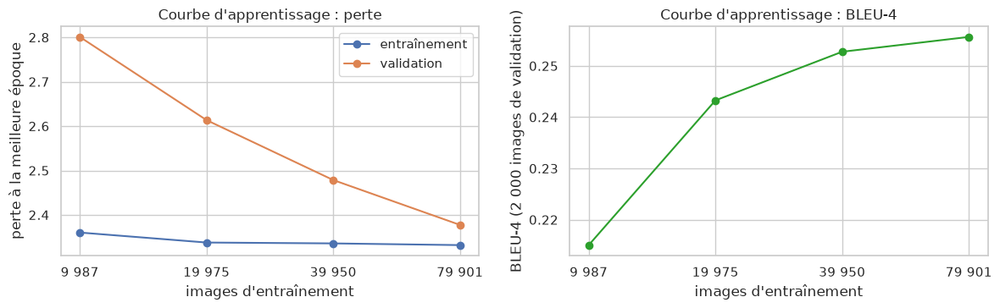

In [17]:
n_train = len(feats["train"])
curve_rows = []
for n in (n_train // 8, n_train // 4, n_train // 2, n_train):
    if n == n_train:
        m, hist = models_["avec attention"], histories["avec attention"]
    else:
        keras.utils.set_random_seed(config.SEED)
        m = model.build_captioner(vocab_size=len(vocab))
        keep = image_index["train"] < n                  # l'ordre de l'échantillon est aléatoire : les n premières images
        batches = model.CaptionBatches(feats["train"][:n], tokens["train"][keep], image_index["train"][keep],
                                       one_per_image=True, **LOADER)
        hist = model.train(m, batches, model.CaptionBatches(feats["val"], tokens["val"], image_index["val"], **LOADER),
                           epochs=EPOCHS, patience=PATIENCE, verbose=0)
    best = hist.loc[hist["val_loss"].idxmin()]
    curve_rows.append({"images d'entraînement": n, "époques effectuées": len(hist), "perte entraînement": best["loss"],
                       "perte validation": best["val_loss"],
                       "BLEU-4 validation": model.bleu(refs["val"], model.generate(m, feats["val"], vocab))["BLEU-4"]})
curve_df = pd.DataFrame(curve_rows).set_index("images d'entraînement")
display(curve_df)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(curve_df.index, curve_df["perte entraînement"], marker="o", label="entraînement")
axes[0].plot(curve_df.index, curve_df["perte validation"], marker="o", label="validation")
axes[0].set_ylabel("perte à la meilleure époque")
axes[0].legend()
axes[1].plot(curve_df.index, curve_df["BLEU-4 validation"], marker="o", color="tab:green")
axes[1].set_ylabel("BLEU-4 (2 000 images de validation)")
for ax in axes:
    ax.set_xscale("log", base=2)
    ax.set_xticks(curve_df.index, [milliers(n) for n in curve_df.index])
    ax.minorticks_off()
    ax.set_xlabel("images d'entraînement")
axes[0].set_title("Courbe d'apprentissage : perte")
axes[1].set_title("Courbe d'apprentissage : BLEU-4")
plt.tight_layout()
plt.show()

In [18]:
first, half, full = curve_df.iloc[0], curve_df.iloc[-2], curve_df.iloc[-1]
loss_drop = half["perte validation"] - full["perte validation"]
display(Markdown(
    f"**Résultats.** Avec {milliers(curve_df.index[0])} images d'entraînement, le modèle atteint une perte de "
    f"validation de {first['perte validation']:.3f} et un BLEU-4 de {first['BLEU-4 validation']:.3f} ; avec "
    f"{milliers(curve_df.index[-1])} images, {full['perte validation']:.3f} et **{full['BLEU-4 validation']:.3f}**. "
    f"Doubler les données de {milliers(curve_df.index[-2])} à {milliers(curve_df.index[-1])} images fait baisser la "
    f"perte de validation de {loss_drop:.3f} et change le BLEU-4 de {full['BLEU-4 validation'] - half['BLEU-4 validation']:+.3f}, "
    f"et l'écart entre perte de validation et perte d'entraînement passe de "
    f"{first['perte validation'] - first['perte entraînement']:+.3f} à {full['perte validation'] - full['perte entraînement']:+.3f}. "
    + ("La perte de validation baisse encore à droite de la courbe : davantage d'images aideraient encore (côté "
       "variance). Le BLEU-4, calculé sur des légendes générées, est une mesure plus bruitée et bouge de façon moins "
       "régulière."
       if loss_drop > 0.02 else
       "La perte de validation s'aplatit : davantage d'images du même type apporteraient peu, c'est le modèle qui "
       "limite (côté biais).")
))

**Résultats.** Avec 9 987 images d'entraînement, le modèle atteint une perte de validation de 2.801 et un BLEU-4 de 0.215 ; avec 79 901 images, 2.377 et **0.256**. Doubler les données de 39 950 à 79 901 images fait baisser la perte de validation de 0.101 et change le BLEU-4 de +0.003, et l'écart entre perte de validation et perte d'entraînement passe de +0.441 à +0.046. La perte de validation baisse encore à droite de la courbe : davantage d'images aideraient encore (côté variance). Le BLEU-4, calculé sur des légendes générées, est une mesure plus bruitée et bouge de façon moins régulière.

## 7. Évaluation sur les images de test

**BLEU** (bilingual evaluation understudy) est le score standard pour du texte généré. Il compte combien de groupes
de 1, 2, 3 et 4 mots consécutifs (n-grammes) de la légende générée apparaissent aussi dans l'une des cinq légendes
de référence, et pénalise les légendes trop courtes. BLEU-1 mesure le choix des mots, BLEU-4 aussi l'ordre des mots
et la formulation. Le score va de 0 à 1 et se calcule sur tout le jeu de test (BLEU de corpus).

Pour donner une échelle, nous évaluons aussi des **légendes humaines** de la même façon : pour chaque image de
test, une de ses cinq légendes est comparée aux quatre autres (quatre références au lieu de cinq, ce qui fait un
peu baisser le score). Les personnes décrivent la même scène avec des mots différents, donc même une bonne
description est loin d'un BLEU de 1.

In [19]:
HUMAN = "légende humaine face aux 4 autres"
test_captions = {name: model.generate(m, feats["test"], vocab) for name, m in models_.items()}
scores = pd.DataFrame({name: model.bleu(refs["test"], caps) for name, caps in test_captions.items()}).T
human = model.bleu([r[1:] for r in refs["test"]], [r[0] for r in refs["test"]])
scores.loc[HUMAN] = human
display(scores)

,BLEU-1,BLEU-2,BLEU-3,BLEU-4
avec attention,0.683,0.503,0.357,0.254
sans attention,0.687,0.504,0.357,0.252
légende humaine face aux 4 autres,0.630,0.428,0.283,0.186


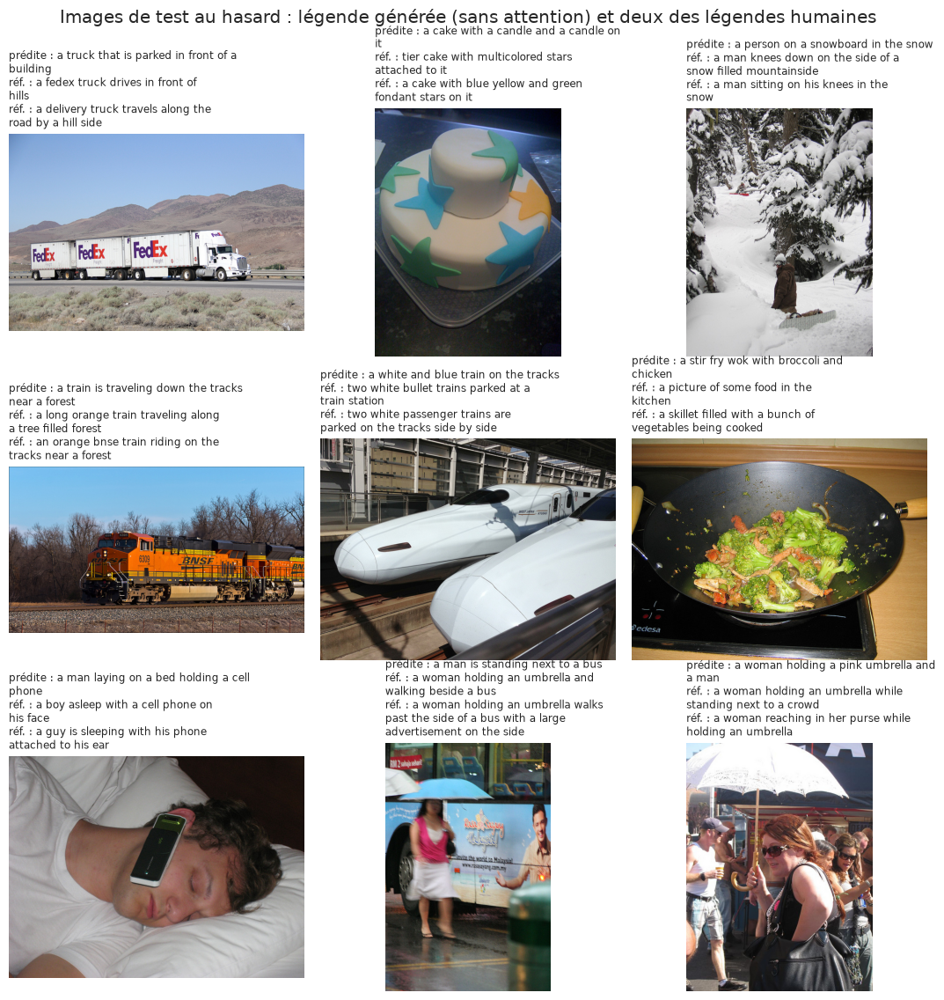

In [20]:
rng = np.random.default_rng(config.SEED)
pick = rng.choice(len(feats["test"]), 9, replace=False)
test_paths = images.loc[images["split"] == "test", "path"].to_numpy()
evaluation.show_captions([cls_data.read_rgb(test_paths[i]) for i in pick], [test_captions[chosen][i] for i in pick],
                         [refs["test"][i] for i in pick])
plt.suptitle(f"Images de test au hasard : légende générée ({chosen}) et deux des légendes humaines", y=1.0)
plt.show()

### 7.1 Où le modèle regarde-t-il ?
Pour le modèle avec attention, on peut afficher les poids sur les 64 régions pour chaque mot généré. Les zones
claires sont les régions qui ont le plus pesé dans le choix du mot. Les cartes peuvent être plus diffuses qu'on ne
l'attendrait : chacun des 64 vecteurs d'InceptionV3 vient du dernier bloc convolutif, dont le champ récepteur
couvre la majeure partie de l'image, donc le modèle n'a pas besoin de regarder l'objet lui-même pour le nommer.

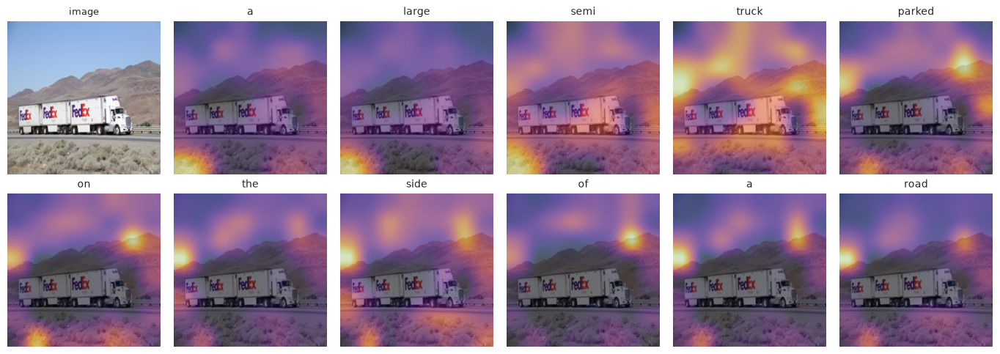

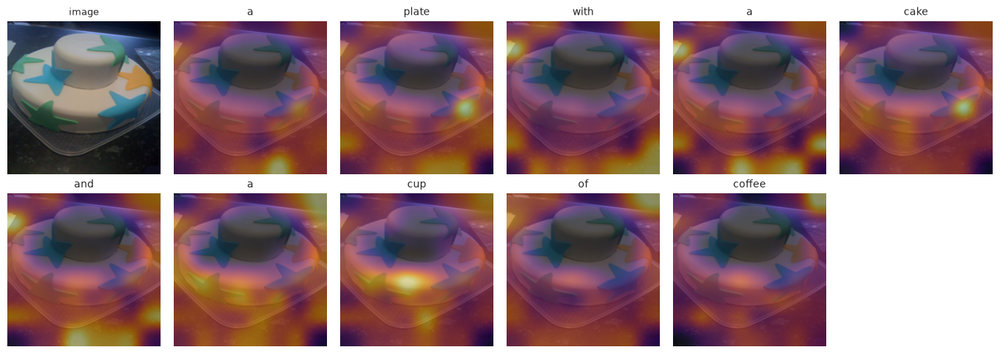

In [21]:
att_model = model.attention_model(models_["avec attention"])
for i in pick[:2]:
    caption = test_captions["avec attention"][i]
    weights = model.attention_maps(att_model, feats["test"][i:i + 1], [caption], vocab)[0]
    evaluation.show_attention(features.load_image(test_paths[i]), caption, weights)
    plt.show()

In [22]:
gen_words = Counter(w for c in test_captions[chosen] for w in c.split())
ref_words = Counter(w for rs in refs["test"] for r in rs[:1] for w in r.split())
train_set = {c for rs in refs["train"] for c in rs}
copied = np.mean([c in train_set for c in test_captions[chosen]])
lengths_gen = np.mean([len(c.split()) for c in test_captions[chosen]])
lengths_ref = np.mean([len(r.split()) for rs in refs["test"] for r in rs])
best = scores.loc[chosen]
display(Markdown(
    f"**Résultats.** Sur les {milliers(len(feats['test']))} images de test, le modèle retenu ({chosen}) atteint un "
    f"BLEU-1 de **{best['BLEU-1']:.3f}** et un BLEU-4 de **{best['BLEU-4']:.3f}** ; "
    + ", ".join(f"{n} : BLEU-4 {scores.loc[n, 'BLEU-4']:.3f}" for n in models_ if n != chosen)
    + f". Les légendes humaines évaluées de la même façon obtiennent un BLEU-4 de {human['BLEU-4']:.3f}. "
    + ("Les deux modèles sont à moins de 0.01 l'un de l'autre : avec ces features, l'attention apporte peu sur le "
       "BLEU, mais elle rend visibles les choix du modèle (section 7.1). "
       if abs(scores.loc["avec attention", "BLEU-4"] - scores.loc["sans attention", "BLEU-4"]) < 0.01 else "")
    + f"Les légendes générées utilisent {milliers(len(gen_words))} mots distincts, contre "
    f"{milliers(len(ref_words))} dans une légende humaine par image"
    + (" : le décodage glouton préfère les mots fréquents et les formulations courantes. " if len(gen_words) < len(ref_words)
       else ". ") + f"{copied:.0%} des légendes générées "
    f"reprennent mot pour mot une légende d'entraînement. Longueur moyenne : {lengths_gen:.1f} mots, contre "
    f"{lengths_ref:.1f} pour les légendes humaines."
))

**Résultats.** Sur les 2 000 images de test, le modèle retenu (sans attention) atteint un BLEU-1 de **0.687** et un BLEU-4 de **0.252** ; avec attention : BLEU-4 0.254. Les légendes humaines évaluées de la même façon obtiennent un BLEU-4 de 0.186. Les deux modèles sont à moins de 0.01 l'un de l'autre : avec ces features, l'attention apporte peu sur le BLEU, mais elle rend visibles les choix du modèle (section 7.1). Les légendes générées utilisent 503 mots distincts, contre 2 279 dans une légende humaine par image : le décodage glouton préfère les mots fréquents et les formulations courantes. 30% des légendes générées reprennent mot pour mot une légende d'entraînement. Longueur moyenne : 9.7 mots, contre 10.5 pour les légendes humaines.

## 8. Étude de cas : photos bruitées, débruitage et qualité des légendes

Le livrable 2 a mesuré le débruiteur avec des scores sur les pixels (PSNR, SSIM). Ce qui compte pour TouNum, c'est
la légende. Nous mesurons ici comment le bruit change les légendes, et si débruiter d'abord les rétablit.

### 8.1 Un bruit plus fort sur les images de test
Nous prenons des images de test, ajoutons le bruit de couleur synthétique du livrable 2 (bruit gaussien sur les
canaux de couleur, puis JPEG qualité 95) à des niveaux bien au-dessus du vrai bruit TouNum, et légendons trois
versions de chaque image : l'image bruitée, l'image débruitée par l'autoencodeur du livrable 2, et l'image traitée
par la règle du pipeline sauvegardée par le livrable 2.

In [23]:
denoiser_path = dn_config.MODELS_DIR / "denoiser.keras"
if QUICK and not denoiser_path.exists():             # le livrable 2 n'a tourné qu'en mode quick
    denoiser_path = Path(tempfile.gettempdir()) / "tounum_quick" / "denoiser.keras"
denoiser = keras.models.load_model(denoiser_path)
dn_settings = json.loads(denoiser_path.with_suffix(".json").read_text())
NOISE_THRESHOLD = float(dn_settings["noise_threshold"])
LEVELS = (0, 10, 20)
case_paths = test_paths[:N_CASE]
case_refs = refs["test"][:N_CASE]


def noisy_versions(paths, sigma, seed):
    """Entrées 299x299 préparées pour les versions bruitée, débruitée et « règle » de chaque image, et les décisions
    de la règle."""
    def make_noisy(args):
        k, p = args
        img = cls_data.read_rgb(p)
        return dn_data.add_noise(img, sigma, np.random.default_rng(seed + k)) if sigma else img

    with ThreadPoolExecutor(8) as ex:
        noisy = list(ex.map(make_noisy, enumerate(paths)))
        estimates = list(ex.map(dn_data.estimate_noise, noisy))
    denoised = [dn_modeling.denoise(denoiser, img) for img in noisy]
    rule = [d if e >= NOISE_THRESHOLD else n for n, d, e in zip(noisy, denoised, estimates)]
    prep = lambda imgs: np.stack([features.prepare(im) for im in imgs])
    return {"bruitée": prep(noisy), "débruitée": prep(denoised), "règle du pipeline": prep(rule)}, np.array(estimates)


t0 = time.perf_counter()
case_rows, case_examples = [], {}
for sigma in LEVELS:
    versions, est = noisy_versions(case_paths, sigma, seed=config.SEED + sigma)
    for variant, inputs in versions.items():
        caps = model.generate(captioner, features.encode(encoder, inputs), vocab)
        case_rows.append({"sigma": sigma, "entrée": variant, **model.bleu(case_refs, caps),
                          "part débruitée": float(np.mean(est >= NOISE_THRESHOLD)) if variant == "règle du pipeline"
                          else float(variant == "débruitée")})
        case_examples[(sigma, variant)] = (inputs[:6], caps[:6])
case_df = pd.DataFrame(case_rows)
display(case_df.pivot(index="entrée", columns="sigma", values="BLEU-4").round(3))
print(f"{len(case_paths)} images de test x {len(LEVELS)} niveaux de bruit x 3 versions en {time.perf_counter() - t0:.0f} s")

sigma,0,10,20
entrée,,,
bruitée,0.257,0.25,0.249
débruitée,0.258,0.26,0.257
règle du pipeline,0.257,0.26,0.257


1000 images de test x 3 niveaux de bruit x 3 versions en 187 s


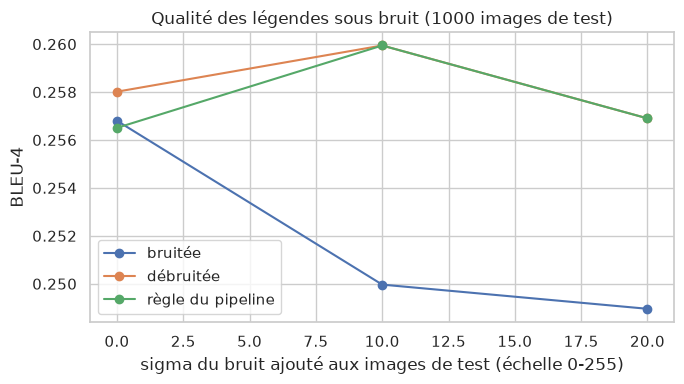

In [24]:
fig, ax = plt.subplots(figsize=(7, 4))
for variant, grp in case_df.groupby("entrée", sort=False):
    ax.plot(grp["sigma"], grp["BLEU-4"], marker="o", label=variant)
ax.set_xlabel("sigma du bruit ajouté aux images de test (échelle 0-255)")
ax.set_ylabel("BLEU-4")
ax.set_title(f"Qualité des légendes sous bruit ({len(case_paths)} images de test)")
ax.legend()
plt.tight_layout()
plt.show()

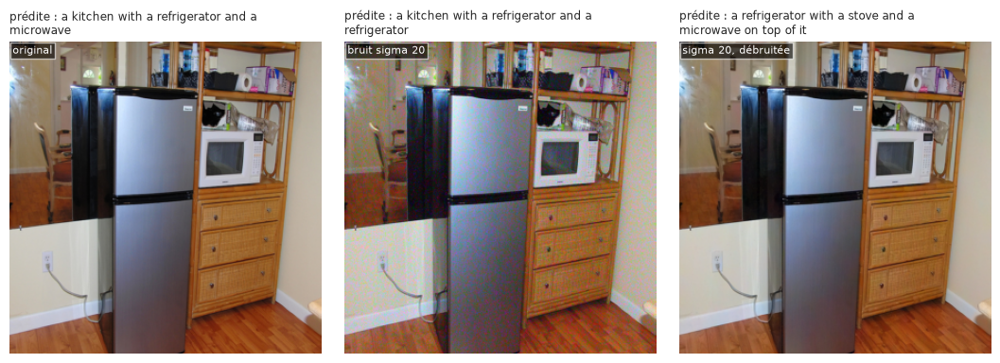

In [25]:
k, top = 3, LEVELS[-1]
imgs = [case_examples[(0, "bruitée")][0][k], case_examples[(top, "bruitée")][0][k], case_examples[(top, "débruitée")][0][k]]
caps = [case_examples[(0, "bruitée")][1][k], case_examples[(top, "bruitée")][1][k], case_examples[(top, "débruitée")][1][k]]
evaluation.show_captions(imgs, caps, cols=3, titles=["original", f"bruit sigma {top}", f"sigma {top}, débruitée"])
plt.show()

In [26]:
piv = case_df.pivot(index="entrée", columns="sigma", values="BLEU-4")
clean_rule = case_df[(case_df["sigma"] == 0) & (case_df["entrée"] == "règle du pipeline")].iloc[0]
drop = piv.loc["bruitée", 0] - piv.loc["bruitée", top]
display(Markdown(
    f"**Résultats.** Sur les images propres, le modèle atteint un BLEU-4 de {piv.loc['bruitée', 0]:.3f}. Avec du "
    "bruit, le BLEU-4 sur les images bruitées et sur les mêmes images débruitées d'abord vaut "
    + " ; ".join(f"{piv.loc['bruitée', s]:.3f} et {piv.loc['débruitée', s]:.3f} à sigma {s}" for s in LEVELS[1:]) + ". "
    + ("Même un bruit de couleur fort change le BLEU-4 de moins de 0.01 : InceptionV3 s'appuie surtout sur les formes "
       "et les textures, que ce bruit laisse intactes, donc pour le captioning le débruiteur compte peu. "
       if abs(drop) < 0.01 else
       f"Un bruit de sigma {top} coûte {drop:.3f} de BLEU-4. ")
    + f"Sur les images propres, la règle du pipeline en débruite {clean_rule['part débruitée']:.0%} et obtient "
    f"{piv.loc['règle du pipeline', 0]:.3f}, contre {piv.loc['bruitée', 0]:.3f} sans aucun débruitage."
))

**Résultats.** Sur les images propres, le modèle atteint un BLEU-4 de 0.257. Avec du bruit, le BLEU-4 sur les images bruitées et sur les mêmes images débruitées d'abord vaut 0.250 et 0.260 à sigma 10 ; 0.249 et 0.257 à sigma 20. Même un bruit de couleur fort change le BLEU-4 de moins de 0.01 : InceptionV3 s'appuie surtout sur les formes et les textures, que ce bruit laisse intactes, donc pour le captioning le débruiteur compte peu. Sur les images propres, la règle du pipeline en débruite 59% et obtient 0.257, contre 0.257 sans aucun débruitage.

### 8.2 Les photos bruitées fournies par TouNum
Ce sont les images du livrable 2. Leurs originaux propres et les cinq légendes COCO de chacune sont connus, et
aucune n'a servi à entraîner le modèle de captioning (section 2). Le débruiteur du livrable 2 a été fine-tuné sur
une partie d'entre elles : nous n'utilisons donc ici que ses 50 images de test. Nous légendons l'original, le
fichier bruité et le fichier bruité passé par la règle du pipeline.

In [27]:
noisy_paths = [p for p in dn_data.extract_noisy() if p.name in set(dn_settings["test_files"])]
noisy_imgs, noisy_info = dn_data.load_noisy(noisy_paths)
original_imgs = dn_data.load_originals(noisy_paths)
coco_ids = originals.set_index("file").loc[noisy_info["file"], "coco_id"].to_numpy()
all_train_caps = data.load_captions("train2017")
tounum_refs = [[" ".join(data.clean_caption(c).split()[1:-1]) for c in all_train_caps.loc[all_train_caps["image_id"] == i, "caption"]]
               for i in coco_ids]
rule_imgs = [dn_modeling.denoise(denoiser, im) if s >= NOISE_THRESHOLD else im
             for im, s in zip(noisy_imgs, noisy_info["noise_sigma"])]
tounum_caps = {}
for variant, imgs in (("original propre", original_imgs), ("fichier bruité", noisy_imgs), ("règle du pipeline", rule_imgs)):
    tounum_caps[variant] = model.generate(captioner, features.encode(encoder, np.stack([features.prepare(im) for im in imgs])), vocab)
tounum_scores = pd.DataFrame({v: model.bleu(tounum_refs, c) for v, c in tounum_caps.items()}).T
display(tounum_scores)
changed = np.mean([a != b for a, b in zip(tounum_caps["original propre"], tounum_caps["fichier bruité"])])

,BLEU-1,BLEU-2,BLEU-3,BLEU-4
original propre,0.750,0.586,0.435,0.328
fichier bruité,0.744,0.587,0.442,0.340
règle du pipeline,0.748,0.590,0.445,0.340


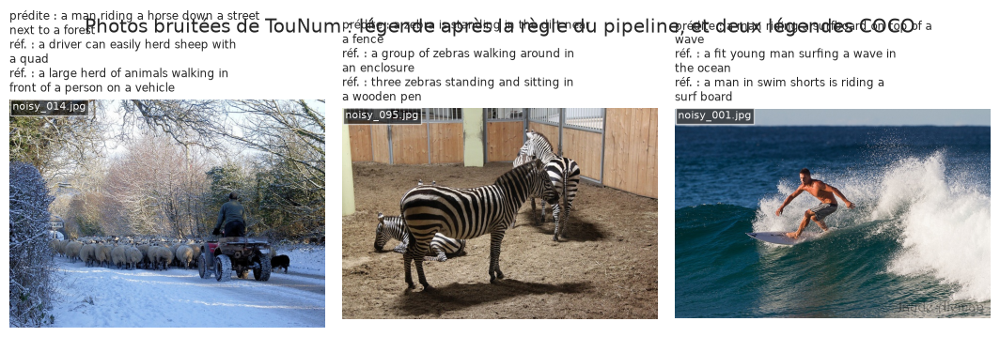

**Résultats.** Sur les 50 photos de test TouNum, le BLEU-4 vaut 0.328 sur les originaux propres, 0.340 sur les fichiers bruités et 0.340 après la règle du pipeline. Le bruit de ces fichiers est léger (livrable 2) : 14% des légendes changent entre l'original et le fichier bruité. Avec si peu d'images et un bruit si léger, de petites différences de BLEU restent dans le bruit de la mesure ; la section 8.1 montre l'effet d'un bruit plus fort.

In [28]:
worst = noisy_info["noise_sigma"].nlargest(3).index
evaluation.show_captions([noisy_imgs[i] for i in worst], [tounum_caps["règle du pipeline"][i] for i in worst],
                         [tounum_refs[i] for i in worst], titles=[noisy_info["file"][i] for i in worst])
plt.suptitle("Photos bruitées de TouNum : légende après la règle du pipeline, et deux légendes COCO", y=1.0)
plt.show()

display(Markdown(
    f"**Résultats.** Sur les {len(noisy_imgs)} photos de test TouNum, le BLEU-4 vaut "
    f"{tounum_scores.loc['original propre', 'BLEU-4']:.3f} sur les originaux propres, "
    f"{tounum_scores.loc['fichier bruité', 'BLEU-4']:.3f} sur les fichiers bruités et "
    f"{tounum_scores.loc['règle du pipeline', 'BLEU-4']:.3f} après la règle du pipeline. Le bruit de ces fichiers est "
    f"léger (livrable 2) : {changed:.0%} des légendes changent entre l'original et le fichier bruité. "
    "Avec si peu d'images et un bruit si léger, de petites différences de BLEU restent dans le bruit de la mesure ; "
    "la section 8.1 montre l'effet d'un bruit plus fort."
))

## 9. Le workflow complet

Les trois livrables sont maintenant enchaînés dans `src/tounum_caption/pipeline.py`. Pour chaque fichier image
d'un dossier :

1. **Filtrer** (livrable 1) : le classifieur de production `models/photo_classifier.keras` donne P(photo) sur
   l'image redimensionnée en 128 x 128. Les images sous 0.5 sont mises de côté, sans légende.
2. **Prétraiter** (livrable 2) : le niveau de bruit de chaque photo est estimé sans référence (Immerkaer). S'il
   atteint le seuil sauvegardé dans `models/denoiser.json`, la photo est débruitée en pleine taille par
   `models/denoiser.keras`.
3. **Légender** (livrable 3) : features InceptionV3, puis décodage glouton avec `models/captioner.keras` et le
   vocabulaire sauvegardé dans `models/captioner.json`.

Le résultat est un tableau avec une ligne par fichier. Le même code tourne en ligne de commande :
`uv run python scripts/caption_folder.py <dossier> --out captions.csv`.

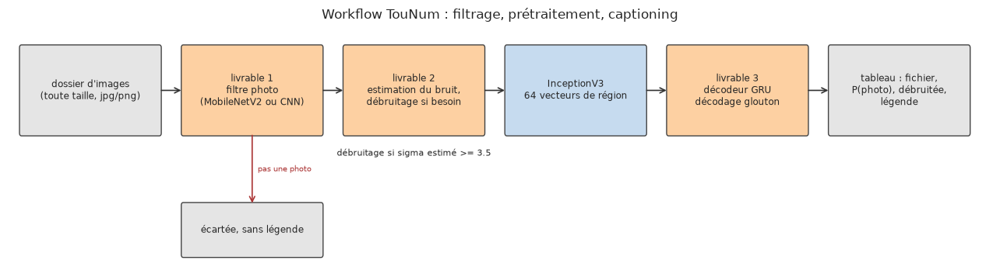

    def run(self, inputs, chunk: int = 64) -> pd.DataFrame:
        """Lance le workflow sur un dossier (ou une liste de fichiers image).

        Renvoie une ligne par fichier : file, path, p_photo, is_photo, noise_sigma, denoised, caption.
        Les non-photos n'ont pas de légende ; les fichiers illisibles sont signalés dans la colonne `caption`.
        """
        paths = list_images(inputs) if isinstance(inputs, (str, Path)) else [Path(p) for p in inputs]
        rows, photo_feats, photo_rows = [], [], []
        t = {"lecture + filtre": 0.0, "débruitage": 0.0, "encodage": 0.0, "légende": 0.0}
        for start in range(0, len(paths), chunk):
            t0 = time.perf_counter()
            images, batch_rows = [], []
            for p in paths[start:start + chunk]:
                row = {"file": p.name, "path": str(p), "p_photo": np.nan, "is_photo": False,
                       "noise_sigma": np.nan, "denoised": False, "caption": ""}
                try:
                    im

In [29]:
evaluation.draw_workflow(NOISE_THRESHOLD)
plt.show()
print(inspect.getsource(pipeline.CaptionPipeline.run))

### 9.1 Sauvegarde du modèle de captioning
Le modèle de captioning est sauvegardé avec ses réglages et son vocabulaire. En mode quick, les modèles des
livrables 1 et 2 sont copiés à côté, pour que l'exécution rapide ne lise ni n'écrive jamais dans `models/`.

In [30]:
SAVE_DIR.mkdir(parents=True, exist_ok=True)
captioner.save(SAVE_DIR / "captioner.keras")
settings = {"model": chosen, "max_len": config.MAX_LEN, "encoder": "InceptionV3 (ImageNet), 299x299, 8x8x2048",
            "vocab": vocab}
(SAVE_DIR / "captioner.json").write_text(json.dumps(settings, ensure_ascii=False))
reloaded = keras.models.load_model(SAVE_DIR / "captioner.keras")
assert model.generate(reloaded, feats["test"][:16], vocab) == test_captions[chosen][:16]
if QUICK:
    classifier_path = cls_config.MODELS_DIR / "photo_classifier.keras"
    if not classifier_path.exists():
        classifier_path = Path(tempfile.gettempdir()) / "tounum_quick" / "photo_classifier.keras"
    for src in (classifier_path, denoiser_path, denoiser_path.with_suffix(".json")):
        if src.parent != SAVE_DIR:
            shutil.copy(src, SAVE_DIR / src.name)
shown_dir = SAVE_DIR.relative_to(config.PROJECT_ROOT) if SAVE_DIR.is_relative_to(config.PROJECT_ROOT) else SAVE_DIR
print(f"Sauvegardés : {shown_dir}/captioner.keras ({(SAVE_DIR / 'captioner.keras').stat().st_size / 1e6:.1f} Mo) et "
      f"{shown_dir}/captioner.json ({milliers(len(vocab))} mots), rechargement vérifié.")

Sauvegardés : models/captioner.keras (71.4 Mo) et models/captioner.json (5 000 mots), rechargement vérifié.


### 9.2 Un dossier de démonstration qui ressemble à une archive TouNum
Pour tester toute la chaîne, nous construisons un dossier qui mélange ce que reçoit TouNum : des photos propres
(images de test COCO), des photos avec un bruit fort, les photos bruitées du livrable 2, et des non-photos issues
du jeu de test étendu du livrable 1 (peintures, schémas, textes scannés, dessins). Aucune de ces images n'a servi à
entraîner l'un des trois modèles. Les noms de fichiers commencent par le vrai type, pour pouvoir vérifier les
décisions du pipeline.

In [31]:
DEMO_DIR = config.DATA_DIR / "demo"
shutil.rmtree(DEMO_DIR, ignore_errors=True)
DEMO_DIR.mkdir(parents=True)
for k, p in enumerate(test_paths[-6:]):
    shutil.copy(p, DEMO_DIR / f"photo_{k}_{Path(p).name}")
rng = np.random.default_rng(config.SEED)
for k, p in enumerate(test_paths[-8:-6]):
    noisy = dn_data.add_noise(cls_data.read_rgb(p), 15, rng)
    Image.fromarray(noisy).save(DEMO_DIR / f"photo_noisy_{k}_{Path(p).name}", quality=95, subsampling=0)
for i in noisy_info["noise_sigma"].nlargest(2).index:
    shutil.copy(noisy_paths[i], DEMO_DIR / f"photo_tounum_{noisy_info['file'][i]}")
cls_meta = pd.read_csv(cls_config.CACHE_DIR / "meta.csv")
non_photos = cls_meta[(cls_meta["split"] == "ext") & (cls_meta["label"] == 0)].groupby("source").sample(2, random_state=config.SEED)
for _, r in non_photos.iterrows():
    name, prefix = Path(r["path"]).name, r["source"].lower()
    shutil.copy(cls_config.PROJECT_ROOT / r["path"], DEMO_DIR / (name if name.lower().startswith(prefix) else f"{prefix}_{name}"))
print(f"{len(list(DEMO_DIR.iterdir()))} fichiers dans {DEMO_DIR.relative_to(config.PROJECT_ROOT)}")

18 fichiers dans data/demo


In [32]:
pipe = pipeline.CaptionPipeline.load(SAVE_DIR, encoder=encoder)
t0 = time.perf_counter()
results = pipe.run(DEMO_DIR)
elapsed = time.perf_counter() - t0
display(results.drop(columns="path").rename(columns=COLS_FR))

,fichier,P(photo),photo,sigma estimé,débruitée,légende
0,painting_01150.jpg,1.140e-03,False,NaN,False,
1,painting_09787.jpg,2.411e-03,False,NaN,False,
2,photo_0_000000092091.jpg,9.943e-01,True,6.888,True,a little boy sitting on a couch with a stuffed animal
3,photo_1_000000473118.jpg,9.955e-01,True,3.378,False,a man on a skateboard in the middle of a skate park
4,photo_2_000000423971.jpg,9.977e-01,True,1.199,False,a toilet with a plunger and a toilet
5,photo_3_000000386277.jpg,9.769e-01,True,2.350,False,a close up of a orange in a tree
6,photo_4_000000299609.jpg,9.868e-01,True,3.983,True,a horse is standing in the grass near a mountain
7,photo_5_000000366611.jpg,9.990e-01,True,13.932,True,a dog is playing with a frisbee in the grass
8,photo_noisy_0_000000453841.jpg,9.862e-01,True,12.401,True,a street with a traffic light and a traffic light
9,photo_noisy_1_000000321557.jpg,9.691e-01,True,15.164,True,a motorcycle parked in a parking lot with a man on the ground


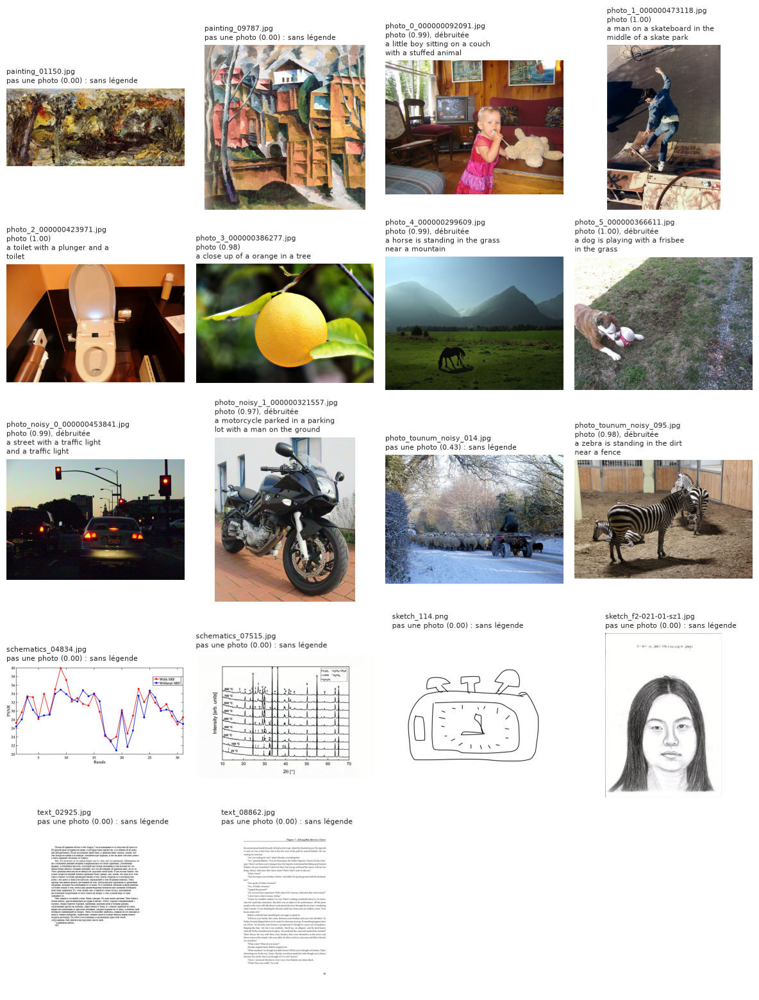

In [33]:
evaluation.show_gallery(results, n=len(results), cols=4)
plt.show()

In [34]:
truth = results["file"].str.startswith("photo")
display(Markdown(
    f"**Résultats.** {len(results)} fichiers traités en {elapsed:.1f} s ({elapsed / len(results):.2f} s par image, "
    f"hors chargement des modèles). Le filtre garde **{int(results['is_photo'].sum())}** images comme photos ; "
    f"{int((results['is_photo'] == truth).sum())} des {len(results)} décisions correspondent au vrai type. "
    f"{int(results['denoised'].sum())} photos ont été débruitées avant le captioning. Temps par étape (s) : "
    + ", ".join(f"{k} {v:.1f}" for k, v in pipe.timings.items()) + "."
))

**Résultats.** 18 fichiers traités en 6.5 s (0.36 s par image, hors chargement des modèles). Le filtre garde **9** images comme photos ; 17 des 18 décisions correspondent au vrai type. 6 photos ont été débruitées avant le captioning. Temps par étape (s) : lecture + filtre 3.1, débruitage 0.3, encodage 3.0, légende 0.1.

## 10. Conclusion, limites et suites

In [35]:
display(Markdown(
    f"**Synthèse.** Modèle de captioning : InceptionV3 (gelé) + décodeur GRU {chosen}, "
    f"{milliers(captioner.count_params())} paramètres entraînés, choisi sur le jeu de validation. Sur "
    f"{milliers(len(feats['test']))} images de test : BLEU-1 {scores.loc[chosen, 'BLEU-1']:.3f}, BLEU-4 "
    f"**{scores.loc[chosen, 'BLEU-4']:.3f}** (légendes humaines : {human['BLEU-4']:.3f}). Sous un bruit de couleur de "
    f"sigma {top}, le BLEU-4 vaut {piv.loc['bruitée', top]:.3f} sans débruitage et {piv.loc['débruitée', top]:.3f} avec ; "
    f"sur les photos de test TouNum, {tounum_scores.loc['fichier bruité', 'BLEU-4']:.3f} sur les fichiers bruités et "
    f"{tounum_scores.loc['règle du pipeline', 'BLEU-4']:.3f} après la règle du pipeline. Le workflow complet a traité "
    f"le dossier de démonstration à {elapsed / len(results):.2f} s par image."
))

**Synthèse.** Modèle de captioning : InceptionV3 (gelé) + décodeur GRU sans attention, 5 947 016 paramètres entraînés, choisi sur le jeu de validation. Sur 2 000 images de test : BLEU-1 0.687, BLEU-4 **0.252** (légendes humaines : 0.186). Sous un bruit de couleur de sigma 20, le BLEU-4 vaut 0.249 sans débruitage et 0.257 avec ; sur les photos de test TouNum, 0.340 sur les fichiers bruités et 0.340 après la règle du pipeline. Le workflow complet a traité le dossier de démonstration à 0.36 s par image.

### Ce que nous avons construit
1. Un **pipeline de données reproductible** pour MS COCO 2017 : échantillonnage, téléchargement des seules images
   échantillonnées, nettoyage des légendes, vocabulaire et encodage.
2. Une **étape de prétraitement des images** fondée sur un CNN pré-entraîné pour la classification (InceptionV3),
   avec un cache de features qui rend l'entraînement rapide.
3. Deux **modèles de captioning** (encodeur CNN + décodeur GRU, avec et sans attention) entraînés en teacher
   forcing, avec les courbes d'entraînement, une courbe d'apprentissage selon le nombre d'images, des scores BLEU
   sur des images jamais vues et des cartes d'attention. Celui qui a le meilleur BLEU-4 de validation est
   sauvegardé pour le workflow.
4. Une **étude de cas** qui relie le livrable 2 au résultat final : l'effet du bruit et du débruitage sur les
   légendes.
5. Le **workflow complet** (filtrer, débruiter, légender) sous forme de code réutilisable, d'un script en ligne de
   commande et de la cellule ci-dessous.

### Limites
- **Légendes en anglais** : MS COCO est annoté en anglais, donc nos légendes le sont aussi. Pour des clients
  francophones, il faudrait ajouter une étape de traduction automatique, ou entraîner le décodeur sur des légendes
  en français.
- **Décodage glouton** : il choisit le mot le plus probable à chaque pas. Les légendes ont tendance à être
  génériques et peuvent reprendre des formulations fréquentes du jeu d'entraînement (mesuré en section 7). Un beam
  search explorerait plusieurs phrases candidates.
- **Données d'entraînement** : 80 000 images COCO. COCO montre des scènes de la vie courante ; les archives de
  TouNum peuvent contenir d'autres sujets (documents anciens, objets techniques) que le modèle n'a jamais vus et
  qu'il décrira avec les mots COCO les plus proches.
- **CNN gelé** : InceptionV3 n'est pas fine-tuné. Fine-tuner ses derniers blocs sur les légendes aide en général,
  pour un coût d'entraînement bien plus élevé.
- **BLEU** récompense le recouvrement de mots avec cinq légendes humaines. Une légende correcte formulée avec
  d'autres mots obtient un score faible : BLEU est un outil de comparaison entre modèles, pas une mesure absolue de
  qualité.
- **Les erreurs s'additionnent le long de la chaîne** : une peinture acceptée par le filtre reçoit une légende
  comme si c'était une photo, et une photo rejetée par le filtre n'en reçoit aucune.

### Suites possibles
- Décodage par beam search et échantillon d'entraînement plus grand (tout COCO 2017) ;
- fine-tuning des derniers blocs d'InceptionV3, ou un encodeur plus récent ;
- des légendes en français (traduction, ou corpus de légendes francophone) ;
- un petit jeu d'images TouNum légendées à la main, pour mesurer la qualité sur leurs vraies archives ;
- journaliser les décisions du pipeline en production (part de photos, part débruitée, longueur des légendes) pour
  détecter une dérive.

### Lancer le workflow sur un nouveau dossier (jour de la soutenance)
Cette dernière cellule est autonome : elle charge les modèles sauvegardés et lance tout le workflow. Il suffit de
changer `INPUT_DIR` et de lancer cette cellule seule ; le reste du notebook n'a pas besoin d'être relancé.

,fichier,P(photo),photo,sigma estimé,débruitée,légende
0,painting_01150.jpg,1.140e-03,False,NaN,False,
1,painting_09787.jpg,2.411e-03,False,NaN,False,
2,photo_0_000000092091.jpg,9.943e-01,True,6.888,True,a little boy sitting on a couch with a stuffed animal
3,photo_1_000000473118.jpg,9.955e-01,True,3.378,False,a man on a skateboard in the middle of a skate park
4,photo_2_000000423971.jpg,9.977e-01,True,1.199,False,a toilet with a plunger and a toilet
5,photo_3_000000386277.jpg,9.769e-01,True,2.350,False,a close up of a orange in a tree
6,photo_4_000000299609.jpg,9.868e-01,True,3.983,True,a horse is standing in the grass near a mountain
7,photo_5_000000366611.jpg,9.990e-01,True,13.932,True,a dog is playing with a frisbee in the grass
8,photo_noisy_0_000000453841.jpg,9.862e-01,True,12.401,True,a street with a traffic light and a traffic light
9,photo_noisy_1_000000321557.jpg,9.691e-01,True,15.164,True,a motorcycle parked in a parking lot with a man on the ground


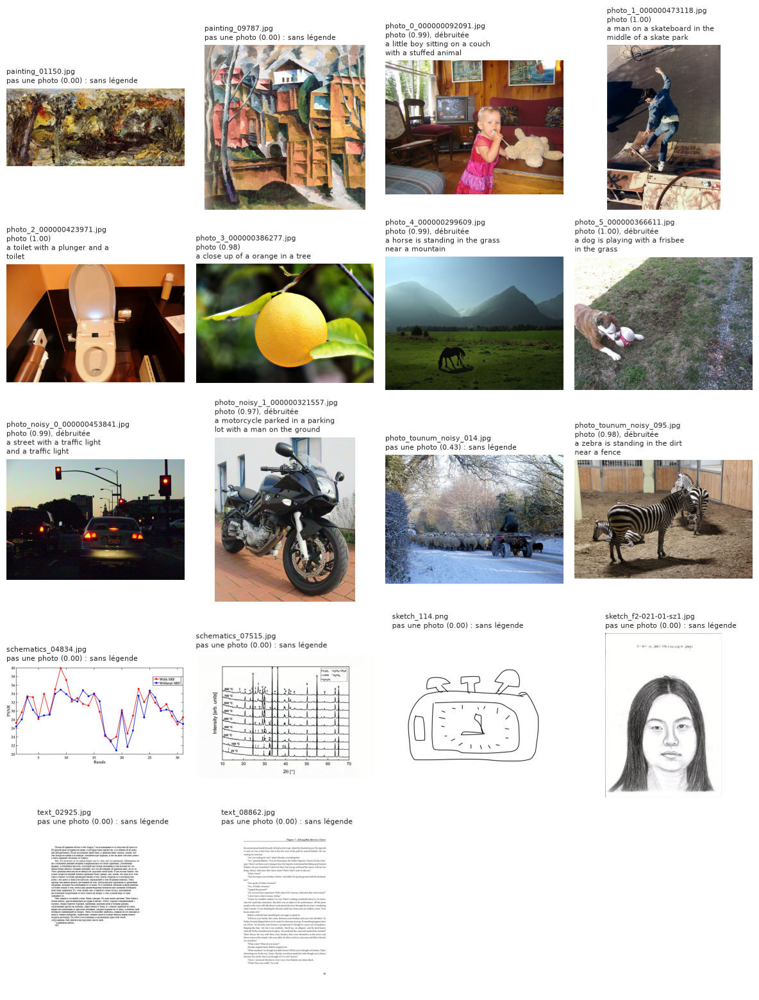

In [36]:
import os, sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import tounum_gpu
tounum_gpu.setup()
import matplotlib.pyplot as plt
from IPython.display import display
from tounum_caption import evaluation
from tounum_caption.pipeline import CaptionPipeline

INPUT_DIR = ROOT / "data" / "demo"                      # <- le dossier à légender
MODELS_DIR = Path(os.environ.get("TOUNUM_MODELS_DIR", ROOT / "models"))   # l'exécution quick utilise une copie temporaire

pipe = CaptionPipeline.load(MODELS_DIR)
results = pipe.run(INPUT_DIR)
results.drop(columns="path").to_csv(ROOT / "data" / "captions.csv", index=False)
display(results.drop(columns="path").rename(columns={"file": "fichier", "p_photo": "P(photo)", "is_photo": "photo",
                                                     "noise_sigma": "sigma estimé", "denoised": "débruitée",
                                                     "caption": "légende"}))
evaluation.show_gallery(results, n=24, cols=4)              # les 24 premières images ; le tableau les liste toutes
plt.show()